In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# plot styling
sns.set_theme(style="whitegrid")

In [2]:
# load dataset

file_path = os.path.normpath("IMDB Dataset.csv")
df = pd.read_csv(file_path)

df.head(5)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Total number of documents
df_len = len(df)
print(f"Total Number of Documents : {df_len}")

Total Number of Documents : 50000


In [4]:
# Class Distribution
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [5]:
# Average document word length

total_word_length = df['review'].str.split().str.len()
print(f"Average Document Word Length : {total_word_length.mean()}")

Average Document Word Length : 231.15694


In [6]:
# Average document char length

avg_char_length = df['review'].str.len().mean()
print(f"Average Document Character Length : {avg_char_length.mean()}")

Average Document Character Length : 1309.43102


In [7]:
# Top 20 most frequent words

word_counter = Counter()
for review in df['review']:
    word_counter.update(review.lower().split())

top_20_words = word_counter.most_common(20)
top_20_df = pd.DataFrame(top_20_words, columns=['Word', 'Frequency'])
print(top_20_df)

     Word  Frequency
0     the     638861
1       a     316615
2     and     313637
3      of     286661
4      to     264573
5      is     204876
6      in     179807
7       i     141587
8    this     138483
9    that     130140
10     it     129614
11  /><br     100974
12    was      93258
13     as      88242
14   with      84590
15    for      84510
16    but      77864
17     on      62890
18  movie      61492
19    are      57009


# TASK 2

In [8]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

In [9]:
# Preprocessing

def remove_html_tags(text: str)-> str:
    return re.sub(r'<.*?>', ' ', text)


def remove_non_chars(text: str)-> str:
    return re.sub(r'[^a-zA-Z\s]', ' ', text)


def preprocess_text(text: str) -> str:
    
    # remove html tags
    text = remove_html_tags(text=text)

    # remove non-alphabet characters and punctuation
    text = remove_non_chars(text=text)

    # tokenisation
    words = text.lower().split()

    preprocessed_words = []
    for word in words:
        if word not in stop_words and len(word) > 1:
            # applying stemming here
            stemmed_word = stemmer.stem(word)

            # lemmatizer
            # lemmatizer.lemmatize(word)
            preprocessed_words.append(stemmed_word)
    
    text = ' '.join(preprocessed_words)
    return text

In [10]:
df['cleaned_review'] = df['review'].apply(preprocess_text)

In [11]:
# Compare original versus Preprocessed

original_5_reviews = df['review'].head(5)
cleaned_5_reviews = df['cleaned_review'].head(5)

compare_df = pd.DataFrame({
    'Original Review': original_5_reviews, 
    'Cleaned Review': cleaned_5_reviews
    })
compare_df

,Original Review,Cleaned Review
0,One of the other reviewers has mentioned that ...,one review mention watch oz episod hook right ...
1,A wonderful little production. <br /><br />The...,wonder littl product film techniqu unassum old...
2,I thought this was a wonderful way to spend ti...,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,basic famili littl boy jake think zombi closet...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei love time money visual stun film...


In [12]:
# Top 20 most frequent words

word_counter = Counter()
for review in df['cleaned_review']:
    word_counter.update(review.lower().split())

top_20_words = word_counter.most_common(20)
top_20_df = pd.DataFrame(top_20_words, columns=['Word', 'Frequency'])
print(top_20_df)

       Word  Frequency
0      movi     103283
1      film      95890
2       one      55453
3      like      45210
4      time      31967
5      good      30195
6      make      30034
7   charact      28364
8       see      28244
9       get      27973
10    watch      27880
11     even      25363
12    stori      25285
13    would      24602
14   realli      23095
15     well      21793
16    scene      21452
17     look      19951
18     show      19914
19     much      19320


# TASK 3

In [13]:
# Represent documents using Bag of Words

from sklearn.feature_extraction.text import CountVectorizer

multi_nb_count_vectorizer = CountVectorizer(max_features=10000)
binary_nb_count_vectorizer = CountVectorizer(max_features=10000, binary=True)

In [14]:
# splitting data to train and test

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    df['cleaned_review'],
    df['sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['sentiment']
)

print(f"Training samples: {len(x_train)}, test_samples : {len(x_test)}")

Training samples: 40000, test_samples : 10000


In [15]:
# Fitting the data using multinomial NB

x_train_multi_nb = multi_nb_count_vectorizer.fit_transform(x_train)
x_test_multi_nb = multi_nb_count_vectorizer.transform(x_test)

# Inspecting Extracted features

print(f"Vocabulary Size: {len(multi_nb_count_vectorizer.vocabulary_)} words")
print(f"x_train_multi_nb Shape: {x_train_multi_nb.shape}")
print(f"Matrix Sparsity: {(1 - x_train_multi_nb.nnz / (x_train_multi_nb.shape[0] * x_train_multi_nb.shape[1])) * 100:.2f}%")


Vocabulary Size: 10000 words
x_train_multi_nb Shape: (40000, 10000)
Matrix Sparsity: 99.12%


In [16]:
# Fitting the data using Binary NB

x_train_binary_nb = binary_nb_count_vectorizer.fit_transform(x_train)
x_test_binary_nb = binary_nb_count_vectorizer.transform(x_test)

# Inspecting Extracted features

print(f"Vocabulary Size: {len(binary_nb_count_vectorizer.vocabulary_)} words")
print(f"x_train_binary_nb Shape: {x_train_binary_nb.shape}")
print(f"Matrix Sparsity: {(1 - x_train_binary_nb.nnz / (x_train_binary_nb.shape[0] * x_train_binary_nb.shape[1])) * 100:.2f}%")

Vocabulary Size: 10000 words
x_train_binary_nb Shape: (40000, 10000)
Matrix Sparsity: 99.12%


# Train and Predict

In [17]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB

mnb_model = MultinomialNB()
mnb_model.fit(x_train_multi_nb, y_train)
y_pred_mnb = mnb_model.predict(x_test_multi_nb)

bnb_model = BernoulliNB()
bnb_model.fit(x_train_binary_nb, y_train)
y_pred_bnb = bnb_model.predict(x_test_binary_nb)

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [19]:
# Multinomial NB statistics

acc_mnb = accuracy_score(y_test, y_pred_mnb)
prec_mnb = precision_score(y_test, y_pred_mnb, pos_label='positive')
rec_mnb = recall_score(y_test, y_pred_mnb, pos_label='positive')
f1_mnb = f1_score(y_test, y_pred_mnb, pos_label='positive')

print(f"MNB Accuracy : {acc_mnb:.4f}")
print(f"MNB Precision : {prec_mnb:.4f}")
print(f"MNB Recall : {rec_mnb:.4f}")
print(f"MNB F1 Score : {f1_mnb:.4f}")

MNB Accuracy : 0.8473
MNB Precision : 0.8558
MNB Recall : 0.8354
MNB F1 Score : 0.8455


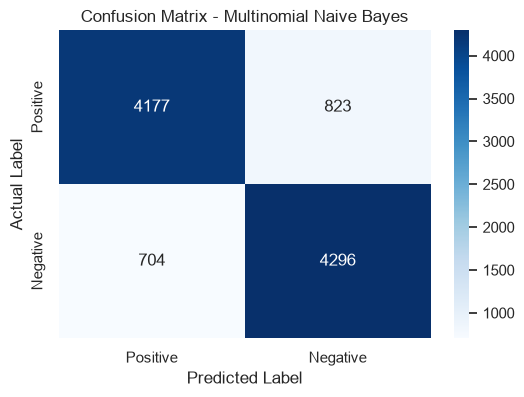

In [20]:
# Confusion Matrix for Multinomial NB

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cc_mnb = confusion_matrix(y_test, y_pred_mnb, labels=['positive', 'negative'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cc_mnb, annot=True, fmt='d', cmap="Blues",
    xticklabels=['Positive', 'Negative'],
    yticklabels=['Positive', 'Negative']
)
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [21]:
# Binary NB statistics

acc_bnb = accuracy_score(y_test, y_pred_bnb)
prec_bnb = precision_score(y_test, y_pred_bnb, pos_label='positive')
rec_bnb = recall_score(y_test, y_pred_bnb, pos_label='positive')
f1_bnb = f1_score(y_test, y_pred_bnb, pos_label='positive')

print(f"BNB Accuracy : {acc_bnb:.4f}")
print(f"BNB Precision : {prec_bnb:.4f}")
print(f"BNB Recall : {rec_bnb:.4f}")
print(f"BNB F1 Score : {f1_bnb:.4f}")

BNB Accuracy : 0.8503
BNB Precision : 0.8578
BNB Recall : 0.8398
BNB F1 Score : 0.8487


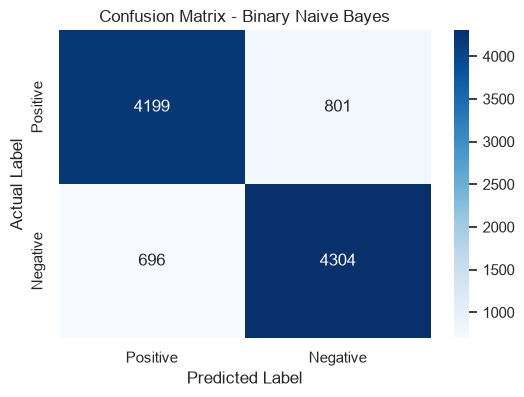

In [22]:
# Confusion Matrix for Binary NB

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cc_bnb = confusion_matrix(y_test, y_pred_bnb, labels=['positive', 'negative'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cc_bnb, annot=True, fmt='d', cmap="Blues",
    xticklabels=['Positive', 'Negative'],
    yticklabels=['Positive', 'Negative']
)
plt.title('Confusion Matrix - Binary Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# Comparision Between Multinomial and Binary Naive Bayes Models

In [23]:
# Create Comparision Dictionary

comparision_data = {
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],
    'Multinomial NB': [
        acc_mnb,
        prec_mnb,
        rec_mnb,
        f1_mnb
    ],
    'Binary NB': [
        acc_bnb,
        prec_bnb,
        rec_bnb,
        f1_bnb
    ]
}

comparision_df = pd.DataFrame(comparision_data)
comparision_df['Multinomial NB'] = comparision_df['Multinomial NB'].round(4)
comparision_df['Binary NB'] = comparision_df['Binary NB'].round(4)

print(f"Model Performance :\n{comparision_df.to_string(index=False)}")

Model Performance :
   Metric  Multinomial NB  Binary NB
 Accuracy          0.8473     0.8503
Precision          0.8558     0.8578
   Recall          0.8354     0.8398
 F1-Score          0.8455     0.8487


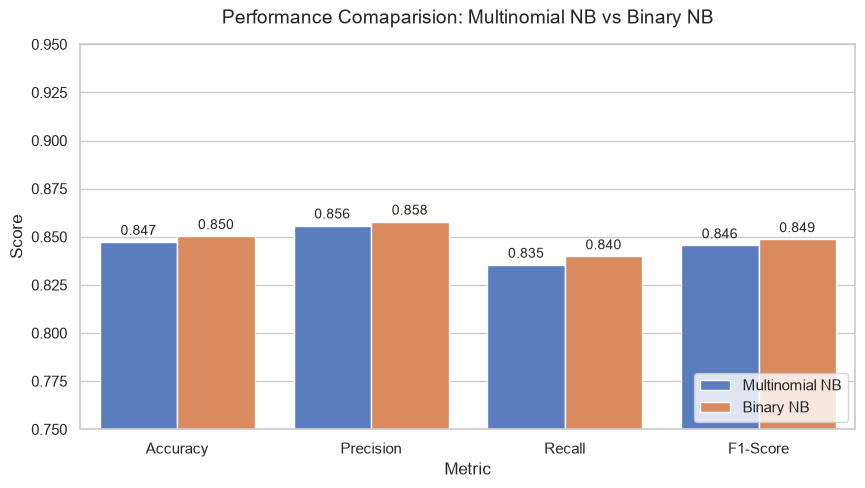

In [24]:
# Bar Graph

df_plot = comparision_df.melt(id_vars='Metric', var_name='Model', value_name='Score')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_plot, x='Metric', y='Score', hue='Model', palette='muted')
plt.title('Performance Comaparision: Multinomial NB vs Binary NB', fontsize=14, pad=15)
plt.ylim(0.75, 0.95)
plt.ylabel('Score')
plt.xlabel('Metric')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(
            f"{p.get_height():.3f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='bottom', fontsize=10, xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(loc='lower right')
plt.show()

# Effect of Smoothing

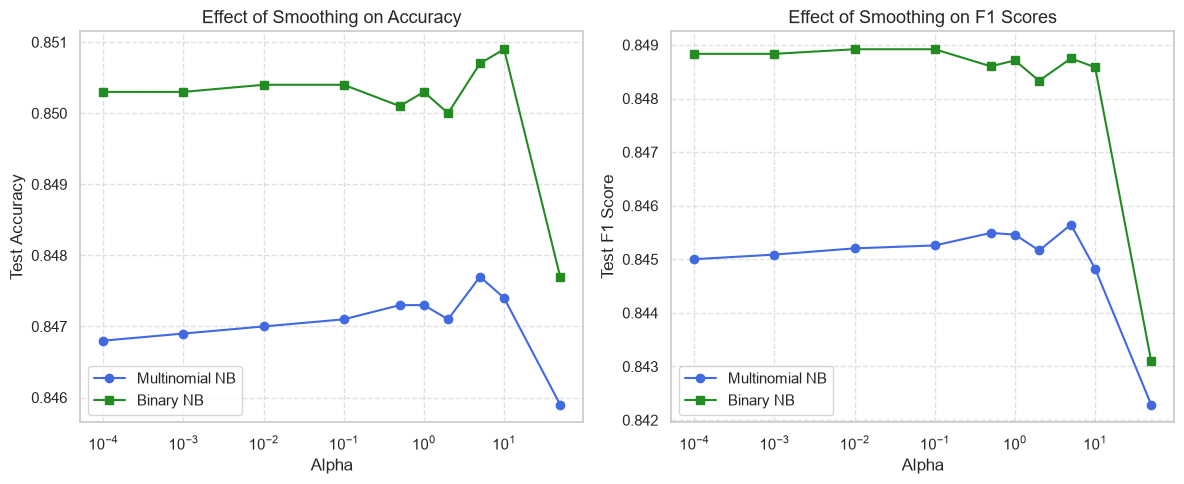

In [25]:
# Adding Alpha Values to solve zero probability problem

alpha_values = [0.0001, 0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]

mnb_accuracies, bnb_accuracies = [], []
mnb_f1_scores, bnb_f1_scores = [], []

for alpha in alpha_values:

    # Multinomial NB
    mnb = MultinomialNB(alpha=alpha)
    mnb.fit(x_train_multi_nb, y_train)
    _y_pred_mnb = mnb.predict(x_test_multi_nb)
    mnb_accuracies.append(accuracy_score(y_test, _y_pred_mnb))
    mnb_f1_scores.append(f1_score(y_test, _y_pred_mnb, pos_label='positive'))

    # Binary NB
    bnb = BernoulliNB(alpha=alpha)
    bnb.fit(x_train_binary_nb, y_train)
    _y_pred_bnb = bnb.predict(x_test_binary_nb)
    bnb_accuracies.append(accuracy_score(y_test, _y_pred_bnb))
    bnb_f1_scores.append(f1_score(y_test, _y_pred_bnb, pos_label='positive'))

smoothing_results = pd.DataFrame({
    'Alpha': alpha_values,
    'MNB Accuracy': mnb_accuracies,
    'MNB F1 Scores': mnb_f1_scores,
    'BNB Accuracy': bnb_accuracies,
    'BNB F1 Scores': bnb_f1_scores
})

plt.figure(figsize=(12, 5))

# Alpha vs Accuracy
plt.subplot(1, 2, 1)
plt.plot(alpha_values, mnb_accuracies, marker='o', label='Multinomial NB', color='royalblue')
plt.plot(alpha_values, bnb_accuracies, marker='s', label='Binary NB', color='forestgreen')
plt.xscale('log')
plt.title('Effect of Smoothing on Accuracy', fontsize=13)
plt.xlabel('Alpha')
plt.ylabel('Test Accuracy')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Alpha vs F1-Score
plt.subplot(1, 2, 2)
plt.plot(alpha_values, mnb_f1_scores, marker='o', label='Multinomial NB', color='royalblue')
plt.plot(alpha_values, bnb_f1_scores, marker='s', label='Binary NB', color='forestgreen')
plt.xscale('log')
plt.title('Effect of Smoothing on F1 Scores', fontsize=13)
plt.xlabel('Alpha')
plt.ylabel('Test F1 Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

# Error Analysis

In [26]:
# Convert to pandas Series/arrays for easy indexing
y_test_arr = y_test.values
y_pred_arr = y_pred_mnb  # or y_pred_bnb

# Find indices of errors
fp_indices = np.where((y_test_arr == 'negative') & (y_pred_arr == 'positive'))[0]
fn_indices = np.where((y_test_arr == 'positive') & (y_pred_arr == 'negative'))[0]

print(f"Total False Positives: {len(fp_indices)}, Total False Negatives: {len(fn_indices)}")

# Pick 5 of each to make 10 examples
selected_error_indices = list(fp_indices[:5]) + list(fn_indices[:5])


Total False Positives: 704, Total False Negatives: 823


In [27]:
# Extract log-likelihoods from the trained MNB model
feature_names = multi_nb_count_vectorizer.get_feature_names_out()
log_prob_pos = mnb_model.feature_log_prob_[1]  # positive class index
log_prob_neg = mnb_model.feature_log_prob_[0]  # negative class index
log_ratio = log_prob_pos - log_prob_neg

# Loop through the 10 misclassified documents
for i, idx in enumerate(selected_error_indices, 1):
    raw_text = x_test.iloc[idx]
    actual = y_test_arr[idx]
    predicted = y_pred_arr[idx]
    
    # Get words present in this review that exist in our vocabulary
    review_words = set(raw_text.split())
    word_scores = []
    
    for w in review_words:
        if w in multi_nb_count_vectorizer.vocabulary_:
            w_idx = multi_nb_count_vectorizer.vocabulary_[w]
            word_scores.append((w, log_ratio[w_idx]))
            
    # Sort words by influence
    word_scores.sort(key=lambda x: x[1])
    top_neg_words = [w for w, score in word_scores[:4]]       # strongest negative words
    top_pos_words = [w for w, score in word_scores[-4:]]      # strongest positive words
    
    print(f"\n--- ERROR EXAMPLE #{i} ---")
    print(f"Actual Class   : {actual.upper()}")
    print(f"Predicted Class: {predicted.upper()} ({'False Positive' if actual == 'negative' else 'False Negative'})")
    print(f"Key Pos Words  : {top_pos_words}")
    print(f"Key Neg Words  : {top_neg_words}")
    print(f"Review Snippet : {raw_text[:250]}...")



--- ERROR EXAMPLE #1 ---
Actual Class   : NEGATIVE
Predicted Class: POSITIVE (False Positive)
Key Pos Words  : ['world', 'wonder', 'love', 'daria']
Key Neg Words  : ['suck', 'excus', 'mutat', 'ok']
Review Snippet : ye mtv realli way market daria start clever teenag angst comment everyth suck make viewer feel better sucki teenag life sitcom mutat deal problem charad use watch daria time love sit watch call movi wonder point daria tell us lead life colleg excus p...

--- ERROR EXAMPLE #2 ---
Actual Class   : NEGATIVE
Predicted Class: POSITIVE (False Positive)
Key Pos Words  : ['rural', 'affection', 'coen', 'portrait']
Key Neg Words  : ['clich', 'potboil', 'ridden', 'filmmak']
Review Snippet : stori bride fair amus engag one filmmak credit set portray rural minnesotan respect ordinarili reserv coast dweller weird though find independ movi brainchild singl person unambiti clich ridden committe brew hollywood potboil portrait rural peopl int...

--- ERROR EXAMPLE #3 ---
Actual Class   : NE